# 05. Query-based detector: RT-DETR

**Question.** How does a detector with bipartite matching and no NMS behave on dense, small objects compared with the CNN detectors under the same budget?

**Protocol** as in notebook 02: fold 0, every 5th training frame, long side 1280, 12 epochs, COCO-pretrained weights, test-like downscaled scored windows, ignored regions as crowd. Model: Ultralytics RT-DETR (hybrid encoder, 300 queries selected from encoder features, Hungarian matching, denoising queries).

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

os.environ.setdefault("VISDET_DATA", "../../hw2/data")
RUNS = Path(os.environ.get("VISDET_RUNS", "../../hw2/runs"))
from visdet.data.index import load_tables
from visdet.viz import gallery, results, style

style.apply()
tables = load_tables()

## Experiments
| run | change from rtdetr-l |
|---|---|
| rtdetr-l-q500 | 500 queries instead of 300 (frames hold up to 180 objects) |
| rtdetr-l-lr | explicit AdamW, lr 1e-4 |
| rtdetr-l-lr2 | explicit AdamW, lr 2e-4, no bias warm-up, beta1 0.9 |
| rtdetr-l-1536 | input 1536 |
| rtdetr-l-24ep | 24 epochs |
| rtdetr-l-downscale | downscale augmentation as in notebook 04 |
| rtdetr-x | larger backbone and encoder |

In [2]:
results.run_table(
    RUNS,
    [
        "rtdetr-l",
        "rtdetr-l-q500",
        "rtdetr-l-lr",
        "rtdetr-l-lr2",
        "rtdetr-l-1536",
        "rtdetr-l-24ep",
        "rtdetr-l-downscale",
        "rtdetr-x",
        "yolo11m",
    ],
)

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,ms_per_image
rtdetr-l,0.3047,0.5334,0.3031,0.0866,0.2491,0.4435,16.9
rtdetr-l-q500,0.3036,0.5324,0.2999,0.0772,0.2499,0.4553,16.9
rtdetr-l-lr,0.0985,0.2264,0.0538,0.0191,0.0698,0.1700,16.8
rtdetr-l-lr2,0.2972,0.5223,0.2918,0.0886,0.2499,0.4294,17.1
rtdetr-l-1536,0.3077,0.5478,0.2984,0.0884,0.2711,0.4085,20.1
rtdetr-l-24ep,0.2925,0.5167,0.2865,0.1021,0.2461,0.4347,16.9
rtdetr-l-downscale,0.3045,0.5299,0.3034,0.0807,0.2589,0.4591,17.1
rtdetr-x,0.3095,0.5416,0.2958,0.0989,0.2619,0.4628,19.1
yolo11m,0.2603,0.4637,0.2570,0.0623,0.2334,0.3812,13.7


## Validation mAP over training against a CNN detector with the same budget

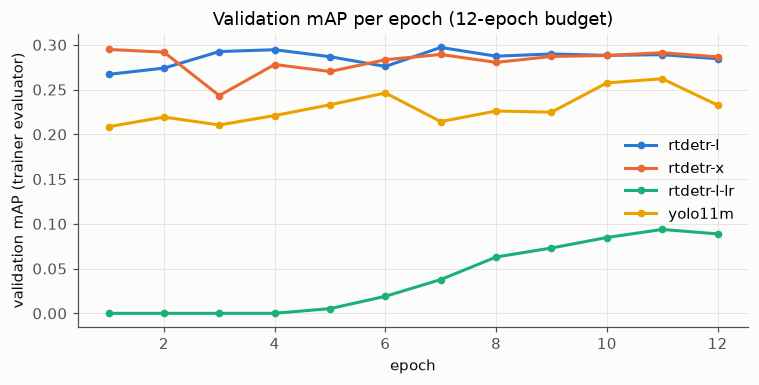

In [3]:
curves = {
    name: results.ultralytics_curve(RUNS, name)
    for name in ["rtdetr-l", "rtdetr-x", "rtdetr-l-lr", "yolo11m"]
}
fig = results.plot_curves(curves, "Validation mAP per epoch (12-epoch budget)")

## Dense and sparse frames

In [4]:
results.density_table(
    tables, RUNS, ["faster-rcnn-proposals", "retinanet-focal", "yolo11m", "rtdetr-l", "rtdetr-x"]
)

"frames: [743, 631, 448]",<=30 objects,31-80,>80
faster-rcnn-proposals,0.2177,0.2790,0.3292
retinanet-focal,0.1954,0.2521,0.3076
yolo11m,0.2429,0.2646,0.3479
rtdetr-l,0.2734,0.2957,0.4000
rtdetr-x,0.2727,0.3228,0.3932


## Results by object size

side,<16,16-32,32-64,64-96,>=96
yolo11m,0.003,0.248,0.533,0.708,0.857
rtdetr-l,0.047,0.462,0.665,0.772,0.919
rtdetr-x,0.087,0.515,0.709,0.812,0.938


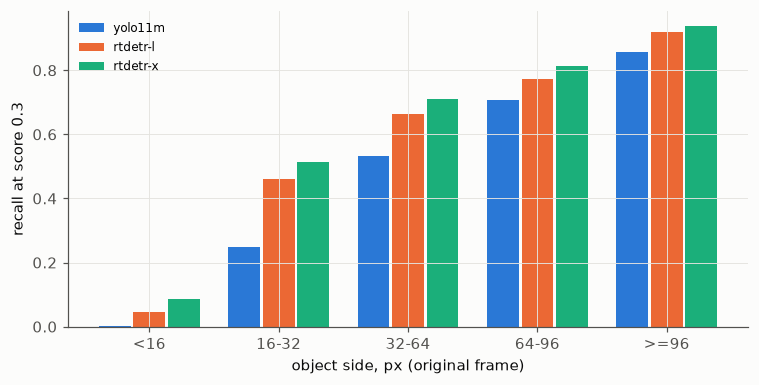

In [5]:
breakdowns = {}
for name in ["yolo11m", "rtdetr-l", "rtdetr-x"]:
    pred = pd.read_parquet(RUNS / name / "fold0" / "val_predictions.parquet")
    breakdowns[name], _ = results.error_breakdown(tables, pred)
fig = results.plot_size_recall(breakdowns)
pd.DataFrame({k: v["recall"] for k, v in breakdowns.items()}).T

## Errors and failure cases

background         48643
class confusion    26617
localisation       23951
duplicate           4617
Name: count, dtype: int64

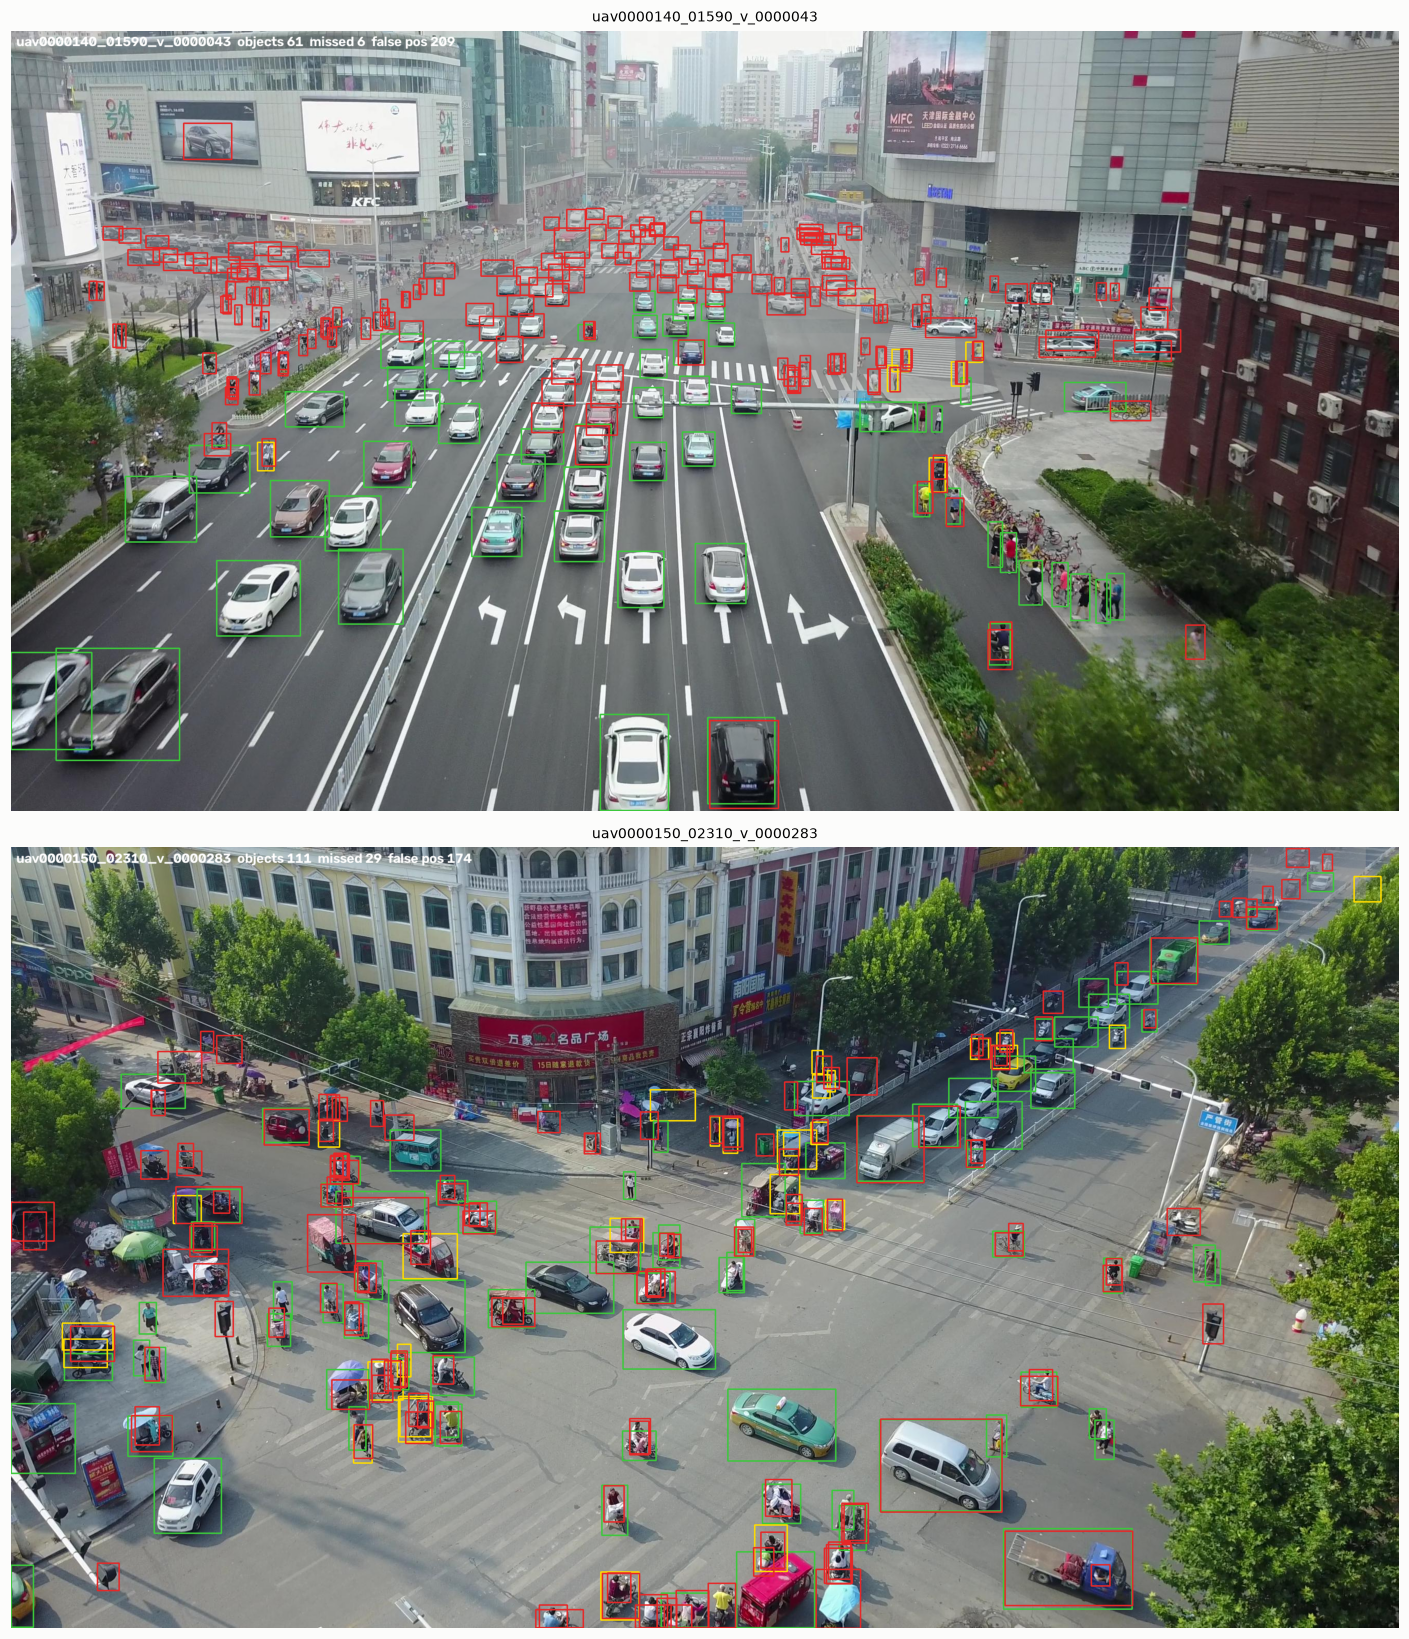

In [6]:
pred = pd.read_parquet(RUNS / "rtdetr-x" / "fold0" / "val_predictions.parquet")
_, fp_kinds = results.error_breakdown(tables, pred)
display(fp_kinds)
worst = results.worst_frames(tables, pred, n=2)
fig, axes = plt.subplots(2, 1, figsize=(13, 15))
for ax, image_id in zip(axes, worst["image_id"], strict=False):
    ax.imshow(gallery.render(tables, pred, image_id, threshold=0.3)[:, :, ::-1])
    ax.set_title(image_id, fontsize=9)
    ax.axis("off")
fig.tight_layout()

## Conclusions
- Bipartite matching assigns one query per object, so duplicates are penalised during training and no NMS is needed; the model keeps at most 300 queries per image, which is enough here (500 queries did not help).
- RT-DETR is the strongest family under the same 12-epoch budget, and its margin is largest on the densest frames and on 16-32 px objects (recall 0.46-0.52 against 0.25 for yolo11m at score 0.3).
- It converges within a few epochs from COCO weights; 24 epochs overfit (-0.012).
- The learning-rate experiment exposed a training-dynamics trap: an explicit AdamW keeps the 0.1 bias warm-up rate and the classification head collapses for three epochs.